# Pendulum Property-Driven Training

This notebook reproduces the property-driven learning loop from the DICE tutorial,
but applied to the *pendulum controller* network used in our repository.

We will:
1. Load a small pendulum dataset (`theta`, `theta_dot`, `u_ref`).
2. Train an MLP controller with a *saturation property loss*  
   enforcing that for all valid states, `u_min <= u <= u_max`.
3. Export the model to ONNX.
4. Verify the trained controller with **Vehicle** + **Marabou**.


### Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path
import json

# From your repo
from pendulum_ml.models.registry import make_model

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device:", device)


Using device: mps


### Load Data and Normalisation

In [2]:
# Paths from your repo
data_dir = Path("../data/processed/pendulum")

X = torch.load(data_dir / "X.pt")  # [N, 3]: theta, theta_dot, error
y = torch.load(data_dir / "y.pt")  # [N, 1]: torque target

with open(data_dir / "norms.json") as f:
    norms = json.load(f)

mu = torch.tensor(norms["mu"][0], dtype=torch.float32)
sd = torch.tensor(norms["sd"][0], dtype=torch.float32)

# Move data and normalization stats to the selected device so training doesn't hit
# "Tensor is on cpu but expected on mps" errors when model/device differ.
X = X.to(device)
y = y.to(device)
mu = mu.to(device)
sd = sd.to(device)

print(f"Dataset: {X.shape[0]} samples, mean/std loaded and moved to {device}.")


Dataset: 25050 samples, mean/std loaded and moved to mps.


### Define the model

In [3]:
def load_snapshot(run: str):
    snap = Path("../experiments") / run / "config.json"
    if not snap.exists():
        raise SystemExit(f"Missing snapshot: {snap}")
    return json.loads(snap.read_text())

run = "run-20251107-173544"
cfg = load_snapshot(run)
model_name = cfg["model"]["name"]
kwargs = cfg["model"].get(model_name, {})
model = make_model(model_name, **kwargs).to(device)
print(model)


MLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


### Define the Property Loss (Saturation)

In [4]:
# Hyperparameters for property
u_min, u_max = -10.0, 10.0

def saturation_loss(u):
    """ Penalise outputs outside [u_min, u_max]. """
    lower = torch.relu(u_min - u)
    upper = torch.relu(u - u_max)
    violation = lower + upper  
    loss = violation.sum()
    return loss


equilibrium = torch.tensor([4.0, 5.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0], device=device)
eps = 0.0001
u_eps = 0.1 # if input-equilibrium < eps, then u < u_eps and if not penalise

def quiet_near_equilibrium_loss(x, u):
    """ Penalise control effort near the equilibrium point (0,0). """
    dist = torch.norm(x - equilibrium, dim=1, p=1)
    mask = (dist < eps).float()
    loss = (mask * torch.relu(torch.abs(u) - u_eps)).sum()
    return loss
    



### Training Loop with Property-Driven Loss

In [5]:
opt = optim.Adam(model.parameters(), lr=1e-3)
n_epochs = 100
lambda_prop = 15.0  # weight for property term

train_loss, prop_violation = [], []

for epoch in range(n_epochs):
    model.train()
    opt.zero_grad()

    # Normalise inputs
    Xn = (X - mu) / sd
    u_pred = model(Xn).squeeze(1)
    u_true = y.squeeze(1)

    # Supervised loss (teacher torque)
    mse = nn.MSELoss()(u_pred, u_true)

    # Property loss
    L_prop = saturation_loss(u_pred)

    loss = mse + lambda_prop * L_prop
    loss.backward()
    opt.step()

    train_loss.append(loss.item())
    prop_violation.append(L_prop.item())

    if epoch % 5 == 0:
        print(f"Epoch {epoch:03d}: total={loss.item():.4f}  mse={mse.item():.4f}  prop={L_prop.item():.4f}")


Epoch 000: total=19.0299  mse=19.0299  prop=0.0000
Epoch 005: total=18.5692  mse=18.5692  prop=0.0000
Epoch 010: total=18.1193  mse=18.1193  prop=0.0000
Epoch 015: total=17.6919  mse=17.6919  prop=0.0000
Epoch 020: total=17.3064  mse=17.3064  prop=0.0000
Epoch 025: total=16.9140  mse=16.9140  prop=0.0000
Epoch 030: total=16.5105  mse=16.5105  prop=0.0000
Epoch 035: total=16.0807  mse=16.0807  prop=0.0000
Epoch 040: total=15.5947  mse=15.5947  prop=0.0000
Epoch 045: total=15.0291  mse=15.0291  prop=0.0000
Epoch 050: total=14.3587  mse=14.3587  prop=0.0000
Epoch 055: total=13.5841  mse=13.5841  prop=0.0000
Epoch 060: total=12.8047  mse=12.8047  prop=0.0000
Epoch 065: total=11.9863  mse=11.9863  prop=0.0000
Epoch 070: total=11.1287  mse=11.1287  prop=0.0000
Epoch 075: total=10.2366  mse=10.2366  prop=0.0000
Epoch 080: total=9.3126  mse=9.3126  prop=0.0000
Epoch 085: total=8.3665  mse=8.3665  prop=0.0000
Epoch 090: total=7.7114  mse=7.7114  prop=0.0000
Epoch 095: total=7.5610  mse=7.5610  

### Visualise Training Dynamics

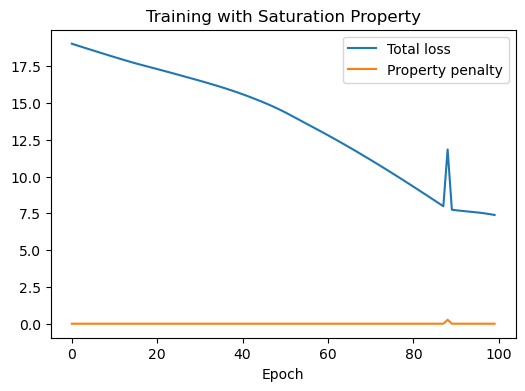

In [6]:
plt.figure(figsize=(6,4))
plt.plot(train_loss, label="Total loss")
plt.plot(prop_violation, label="Property penalty")
plt.xlabel("Epoch")
plt.legend()
plt.title("Training with Saturation Property")
plt.show()


### Check Property Satisfaction

In [7]:
N_test = 5000
theta = torch.empty(N_test).uniform_(-3.1416, 3.1416)
theta_dot = torch.empty(N_test).uniform_(-10, 10)
err = -theta  # assume setpoint=0

Xtest = torch.stack([theta, theta_dot, err], dim=1).to(device)
Xtest_n = (Xtest - mu) / sd
u_pred = model(Xtest_n).detach().cpu().squeeze()

violations = ((u_pred < u_min) | (u_pred > u_max)).float().mean()
print(f"Fraction of violations for property driven training: {violations*100:.2f}%")


# Load ckpt for comparison
ckpt_path = Path("../models/checkpoints") / f"{run}.pt"

model_ckpt = make_model(model_name, **kwargs).to(device)
model_ckpt.load_state_dict(torch.load(ckpt_path, map_location=device))
model_ckpt.eval()
u_pred_ckpt = model_ckpt(Xtest_n).detach().cpu().squeeze()
violations_ckpt = ((u_pred_ckpt < u_min) | (u_pred_ckpt > u_max)).float().mean()
print(f"Fraction of violations for checkpoint model: {violations_ckpt*100:.2f}%")


Fraction of violations for property driven training: 40.84%
Fraction of violations for checkpoint model: 59.94%


### Export to ONNX

In [8]:
out_path = Path("../models/onnx/pendulum_ctrl_property.onnx")
out_path.parent.mkdir(parents=True, exist_ok=True)

dummy = torch.zeros(1, 3, dtype=torch.float32).to(device)
torch.onnx.export(model, dummy, out_path,
                  input_names=["input"], output_names=["output"],
                  opset_version=13)
print("Exported:", out_path)

Exported: ../models/onnx/pendulum_ctrl_property.onnx


/var/folders/4z/v9y67y7x27152tcm86prnvwc0000gn/T/ipykernel_33554/1071074399.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  torch.onnx.export(model, dummy, out_path,


In [9]:
!vehicle verify \
    --specification ../specs/pendulum_controller.vcl \
    --network ctrlNet:../models/onnx/pendulum_ctrl_property.onnx \
    $(cat ../specs/pendulum_params.cli) \
    --verifier Marabou



In order to provide support, Vehicle has automatically converted the strict inequalities to non-strict inequalites. This is not sound, but errors will be at most the floating point epsilon used by the verifier, which is usually very small (e.g. 1e-9). However, this may lead to unexpected behaviour (e.g. loss of the law of excluded middle).

See https://github.com/vehicle-lang/vehicle/issues/74 for further details.


  In queries 1 and 2:
    ctrlNet₀[input]!0 - no lower or upper bound



In order to provide support, Vehicle has automatically converted the strict inequalities to non-strict inequalites. This is not sound, but errors will be at most the floating point epsilon used by the verifier, which is usually very small (e.g. 1e-9). However, this may lead to unexpected behaviour (e.g. loss of the law of excluded middle).

See https://github.com/vehicle-lang/vehicle/issues/74 for further details.


  In queries 1 and 2:
    ctrlNet₀[input]!0 - no lower or upper bound



In order to 